# 05 - Complete Report, Power Analysis, and Data Audit

This notebook consolidates the final experimental metadata, direct measurements, derived pulse energies, confidence classifications, complete source-file inventory, and the outputs generated by the spatial, temporal, and spectral notebooks. It is intentionally conservative: a number is labeled as measured, derived, provisional, conditional, or unsupported according to what the apparatus actually resolves.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image


def _locate_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for base in [start, *start.parents]:
        if (base / "experiment_metadata.json").is_file() and (base / "outputs").is_dir():
            return base.resolve()
        for child in list(base.glob("Laser_Characterization_Project*")) + list(base.glob("laser_characterization_project*")):
            if child.is_dir() and (child / "experiment_metadata.json").is_file() and (child / "outputs").is_dir():
                return child.resolve()
    raise FileNotFoundError("Could not locate the extracted laser-characterization project folder.")

ROOT = _locate_project_root()
OUT = ROOT / "outputs"
FIG = ROOT / "figures"
metadata = json.loads((ROOT / "experiment_metadata.json").read_text())
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
print("Project:", ROOT)
print("Project version:", metadata.get("project_version"))

Project: <project root>
Project version: 4.0-fixed


## Final measurement metadata

The values below are the experimenter-supplied final metadata. They supersede any provisional assumptions in earlier exploratory analysis.

In [2]:
display(pd.json_normalize(metadata, sep="."))

,project_version,analysis_date,unresolved_inputs,finalized_date,report_scope,reporting_policy.significant_figures,reporting_policy.uncertainty_policy,reporting_policy.claim_classes,source_532_nm.manufacturer,source_532_nm.model,source_532_nm.operating_mode,source_532_nm.nominal_wavelength_nm,source_532_nm.output_power_mW_user_reported,source_532_nm.separate_from_gsl106a,source_532_nm.warmup_time_min_user_estimate,source_532_nm.manufacturer_power_specification_used,source_532_nm.average_power_meter,source_1064_nm.manufacturer,source_1064_nm.model,source_1064_nm.output_coupling,source_1064_nm.modes_in_dataset,source_1064_nm.external_trigger,source_1064_nm.intended_repetition_rate_hz,source_1064_nm.warmup_time_min_user_estimate,spatial_532_nm.camera,...,spectral_setup.slits,spectral_setup.gratings_grooves_per_mm,spectral_setup.software,spectral_setup.dark_processing,spectral_setup.binning,spectral_setup.accumulations,spectral_setup.rtd_interpretation,spectral_setup.wavelength_calibration.lamp,spectral_setup.wavelength_calibration.visible_reference_lines_nm,spectral_setup.wavelength_calibration.method,spectral_setup.wavelength_calibration.near_1064_reference_available,spectral_setup.wavelength_calibration.consequence,power_measurement.meter_console,power_measurement.sensor,power_measurement.location,power_measurement.attenuation_correction_applied,power_measurement.symbol_semantics.>,power_measurement.symbol_semantics.<,power_measurement.symbol_semantics.~,power_measurement.measurements.COMPASS_532_CW,power_measurement.measurements.GSL106A_CW,power_measurement.measurements.GSL106A_ps_200kHz,power_measurement.measurements.GSL106A_1ns_200kHz,power_measurement.measurements.GSL106A_65ns_200kHz,power_measurement.uncertainty_policy
0,4.0-fixed,2026-08-31,"[PDA36A responsivity at 1064 nm for the specific detector, Reflective ND transmission at 1064 nm for each temporal a...",2026-08-31,"Complete spatial, temporal, spectral, and power characterization using all supplied files.",At least three significant figures where supported by sampling and calibration; extra digits are retained in CSV fil...,Use observed repeatability standard deviations when independent repeats exist. Treat curve-fit covariance as conditi...,"[supported, supported_with_caveat, provisional, not_supported]",Coherent,COMPASS 315M-100,continuous wave,532,>130 mW,True,2,False,Thorlabs PM100D with S121C sensor,Thorlabs,GSL106A,fiber,"[picosecond, 1 ns, 65 ns, CW spectral]",True,200000,2,Basler acA3088-57uc,...,Fully closed or minimum practical separation unless filename states otherwise,"[300, 1200, 1800]",LabSpec 6,signal-dark,1,1,0 s means live real-time display,Mercury lamp,"[435.8, 546.1]",Grating-specific wavelength offsets adjusted until the two visible peaks matched to four significant figures,False,Absolute wavelength accuracy near 1064 nm is unverified; measured widths remain more robust than absolute centers.,Thorlabs PM100D,Thorlabs S121C,Free-space output immediately after the F280APC-1064 collimator for the GSL106A; before any attenuation,False,strict lower bound,strict upper bound,approximate,>130 mW,>16 mW,>1.35 uW,>9.4 uW,~333 uW; observed approximately 330-340 uW,"No arbitrary combined uncertainty is assigned without the sensor calibration certificate, repeated readings, and env..."


## Optical power, pulse energy, and photon-number scale

For the pulsed modes, `E_pulse = P_average/f_rep`. Lower-bound powers remain lower-bound energies. The 65 ns value is retained as an approximate observed range. Peak power is not calculated as a measurement because the optical temporal profile is unresolved.

,source,wavelength_nm,mode,repetition_rate_Hz,reported_power,bound_type,power_low_W,power_high_W,representative_power_W,pulse_energy_low_J,pulse_energy_high_J,photons_per_pulse_low,photons_per_pulse_high,photon_flux_low_per_s,interpretation
0,Coherent COMPASS 315M-100,532.0,CW,NaN,>130 mW,lower bound,0.130000,NaN,0.130000,NaN,NaN,NaN,NaN,3.481595e+17,CW optical power lower bound at the measurement point.
1,Thorlabs GSL106A,1064.0,CW,NaN,>16 mW,lower bound,0.016000,NaN,0.016000,NaN,NaN,NaN,NaN,8.570080e+16,CW optical power lower bound after the fiber collimator and before attenuation.
2,Thorlabs GSL106A,1064.0,ps,200000.0,>1.35 uW,lower bound,0.000001,NaN,0.000001,6.750000e-12,NaN,3.615503e+07,NaN,7.231005e+12,Pulse-energy lower bound. Peak power is not determined because optical pulse duration and phase were not measured.
3,Thorlabs GSL106A,1064.0,1 ns,200000.0,>9.4 uW,lower bound,0.000009,NaN,0.000009,4.700000e-11,NaN,2.517461e+08,NaN,5.034922e+13,Pulse-energy lower bound. The PDA36A trace does not resolve a 1 ns optical pulse.
4,Thorlabs GSL106A,1064.0,65 ns,200000.0,~333 uW (observed 330-340 uW),observed approximate range,0.000330,0.00034,0.000335,1.650000e-09,1.700000e-09,8.837895e+09,9.105710e+09,1.767579e+15,Approximate pulse-energy range. Nominal 65 ns may be used only for a clearly labeled conditional average-within-puls...


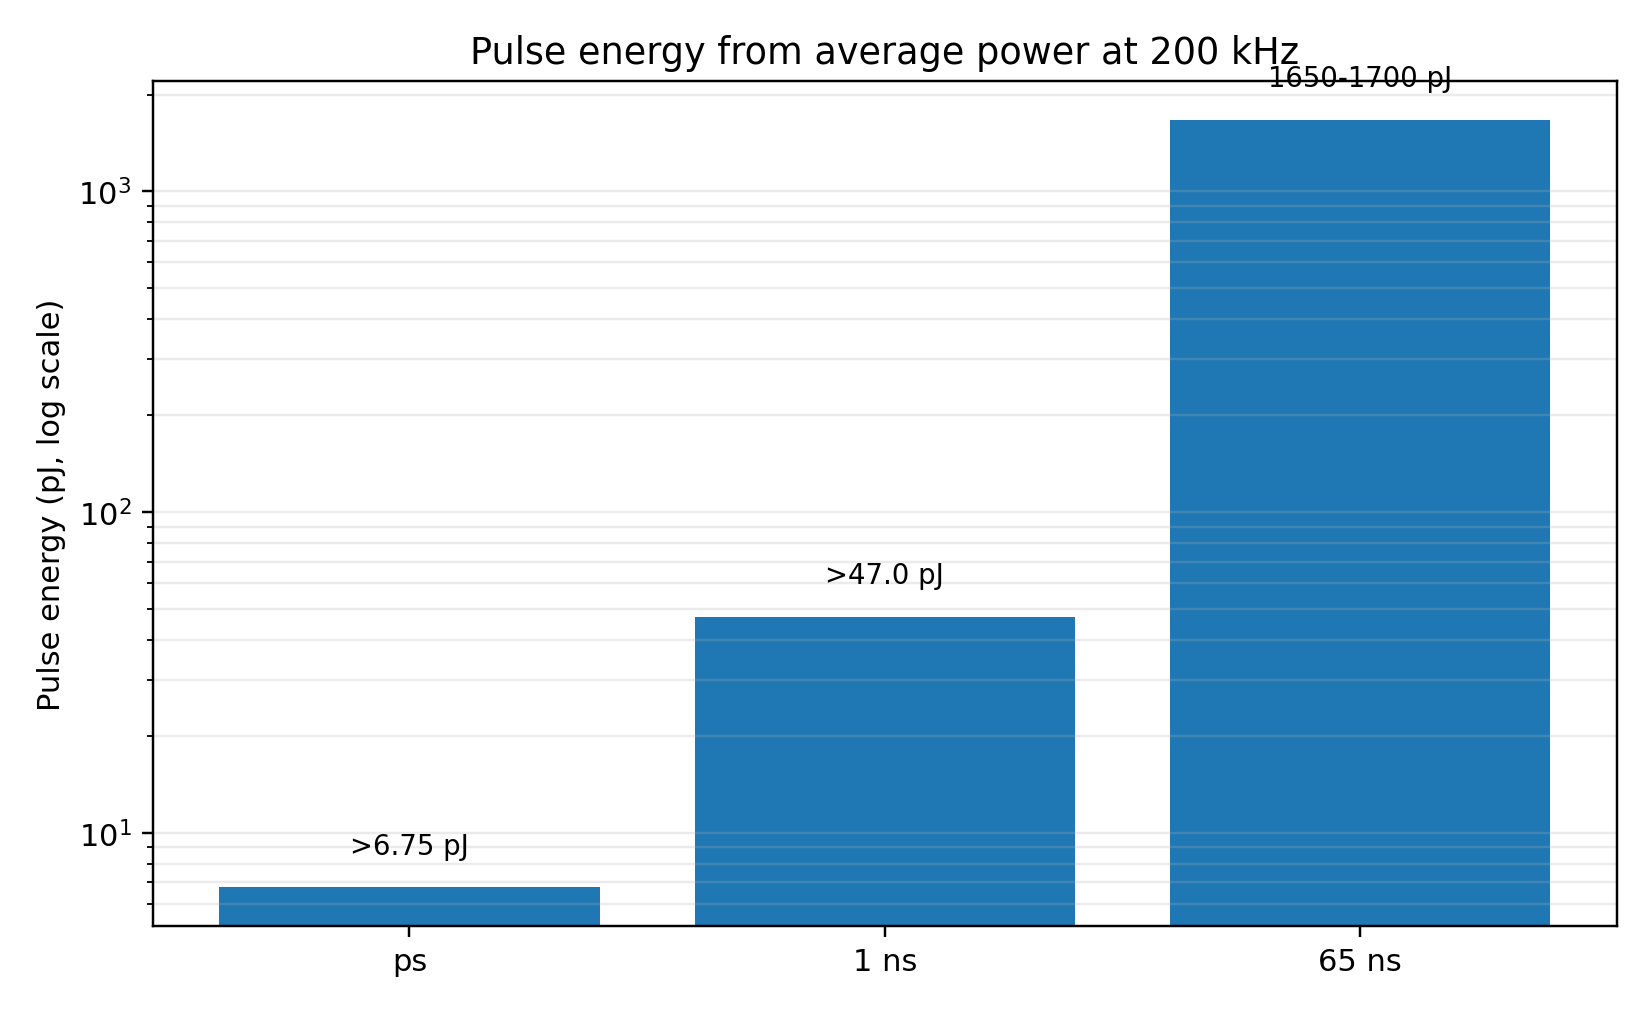

In [3]:
power = pd.read_csv(OUT / "power_energy_summary.csv")
display(power)
display(Image(filename=str(FIG / "pulse_energy_v3.png")))

## Measurement confidence matrix

“High as electrical width” does not mean “high confidence optical pulse duration.” Confidence is attached to the precise quantity named in each row.

In [4]:
confidence = pd.read_csv(OUT / "measurement_confidence_matrix.csv")
display(confidence)

,quantity,reported_result,confidence,basis_and_limitation
0,532 nm optical power,>130 mW,Moderate,Direct PM100D/S121C reading reported as a strict lower bound; no calibration certificate or repeat series supplied.
1,532 nm sensor-plane centroid and beam dimensions,Per-frame values in spatial tables,Moderate,"Direct camera data and independent repeats; limited by saturation, no dedicated dark frame, background structure, an..."
2,532 nm beam ellipticity/orientation,Per-frame values in spatial tables,Moderate,Meaningful for the selected highest-intensity lobe; sensitive to aperture and background.
3,"532 nm M2, major axis",2.539 provisional,Low / provisional,"Caustic fit exists, but saturation near waist, limited valid z coverage, unknown z uncertainty, and secondary struct..."
4,"532 nm M2, minor axis",1.814 provisional,Low / provisional,Same limitations as major axis.
5,1064 nm repetition rate,Approximately 200.0003 kHz,High for measurement chain,"Long records and hysteretic trigger-edge detection agree across modes; this is trigger-chain repetition rate, not a ..."
6,ps electrical response FWHM,20.8896 ns,High as electrical width,The exported waveform supports this electrical response width; it is not the optical pulse duration.
7,1 ns electrical response FWHM,32.3680 ns,High as electrical width,The detector/electronics do not resolve a 1 ns optical pulse.
8,65 ns electrical response FWHM,49.0250 ns,Moderate as electrical width,Partially resolved but detector-convolved and affected by ringing; not a calibrated optical duration.
9,ps pulse energy,>6.75 pJ,Moderate lower bound,Derived exactly from the reported lower-bound average power and measured/nominal 200 kHz rate.


## Complete source-file audit

In [5]:
inventory = pd.read_csv(OUT / "source_data_inventory.csv")
summary = inventory.groupby(["domain", "extension"], dropna=False).agg(files=("source_id", "count"), uncompressed_bytes=("uncompressed_bytes", "sum")).reset_index()
display(summary)
print("Total source entries:", len(inventory))
display(inventory)

,domain,extension,files,uncompressed_bytes
0,Spatial (532 nm),.png,22,188446173
1,Spatial (532 nm),.raw,36,458901504
2,Spectral (532/1064 nm),.txt,42,764652
3,Temporal (1064 nm),.csv,19,484128877


Total source entries: 119


,source_id,domain,archive_path,file_name,extension,uncompressed_bytes,compressed_bytes,crc32,sha256_from_source_manifest,analysis_status
0,1,Spectral (532/1064 nm),532 and 1064/1064nm_Spectrum/Laser_1064nm_Mode_CW_RTD_0s_Slit_0um_Grad_300_ND_3.txt,Laser_1064nm_Mode_CW_RTD_0s_Slit_0um_Grad_300_ND_3.txt,.txt,18654,7689,d74cfc15,7ea1542a2aa4f4d92d961f83411471475c18d24728b66478140120782293f093,Included in domain parser or retained as supporting acquisition file
1,2,Temporal (1064 nm),532 and 1064/Pulse_Data/Improper_Impedance_CH1_1Mohm/1_ns_Mode/Mode_1ns_ND_0_Gain_0db_ExtTrigger_200kHz_Chopper_987H...,Mode_1ns_ND_0_Gain_0db_ExtTrigger_200kHz_Chopper_987Hz_TimeDiv_108us.csv,.csv,76649935,5216830,0db875ff,2aea7bdbddd6ba9183db1c59ae8f0df0c6c472972ca40e2b7ddd8c8e95ba8a49,Included in domain parser or retained as supporting acquisition file
2,3,Temporal (1064 nm),532 and 1064/Pulse_Data/Improper_Impedance_CH1_1Mohm/1_ns_Mode/Mode_1ns_ND_0_Gain_0db_ExtTrigger_200kHz_Chopper_987H...,Mode_1ns_ND_0_Gain_0db_ExtTrigger_200kHz_Chopper_987Hz_TimeDiv_2us.csv,.csv,1418368,98197,de86beae,8dc55ea149b29132c9cea17f190c6bcc3c6bd6ae4502254cc5cbfc5ed9f7f381,Included in domain parser or retained as supporting acquisition file
3,4,Temporal (1064 nm),532 and 1064/Pulse_Data/Improper_Impedance_CH1_1Mohm/1_ns_Mode/Mode_1ns_ND_0_Gain_0db_ExtTrigger_200kHz_Chopper_987H...,Mode_1ns_ND_0_Gain_0db_ExtTrigger_200kHz_Chopper_987Hz_TimeDiv_300ns.csv,.csv,217238,16659,60e5cb75,39d56ed62725201e350513964853803114b93c192b255e33191aa14d678df84f,Included in domain parser or retained as supporting acquisition file
4,5,Temporal (1064 nm),532 and 1064/Pulse_Data/Improper_Impedance_CH1_1Mohm/1_ns_Mode/Mode_1ns_ND_0_Gain_0db_ExtTrigger_200kHz_Chopper_987H...,Mode_1ns_ND_0_Gain_0db_ExtTrigger_200kHz_Chopper_987Hz_TimeDiv_33ns.csv,.csv,75230,13863,fffc5d96,e13ad01efb80a61d3d0c44b268050f16805bbf550c5008a19d069acdd92e4972,Included in domain parser or retained as supporting acquisition file
...,...,...,...,...,...,...,...,...,...,...
114,115,Spatial (532 nm),532 and 1064/532nm_YesFocal_Gain0_Exposure10k_BayerRG12/Position_170mm.png,Position_170mm.png,.png,8314679,8317182,bc2a7537,38cd7d562f69593fafbfaeef8207f9cb58e0303c9e4a2b40af429ee70614f161,Included in domain parser or retained as supporting acquisition file
115,116,Spatial (532 nm),532 and 1064/532nm_YesFocal_Gain0_Exposure10k_BayerRG12/Position_200mm.png,Position_200mm.png,.png,8271293,8273791,a3afbb33,235978eb6ea6102c505518d75051aaaef58e0c2b76c13c2952efa482ee18bb95,Included in domain parser or retained as supporting acquisition file
116,117,Spatial (532 nm),532 and 1064/532nm_YesFocal_Gain0_Exposure10k_BayerRG12/Position_250mm.png,Position_250mm.png,.png,8414233,8416777,80f0bf77,e08a4f8f181630a1c892a5494e96679c60292527d0759f93c47bd6facaeb3e69,Included in domain parser or retained as supporting acquisition file
117,118,Spatial (532 nm),532 and 1064/532nm_YesFocal_Gain0_Exposure10k_BayerRG12/Position_70mm.png,Position_70mm.png,.png,8307963,8310477,f2039d69,908aa3947a444f7e16a082a2203570f7b44fe61e2a4106ef9781c0445f16d861,Included in domain parser or retained as supporting acquisition file


## Analysis-output catalog

In [6]:
catalog = pd.read_csv(OUT / "analysis_output_catalog.csv")
display(catalog)

,file,extension,bytes,rows,columns,column_names
0,average_power_inputs.csv,.csv,659,5,11,source | mode | wavelength_nm | repetition_rate_Hz | power_relation | power_value | power_unit | measurement_locatio...
1,measurement_confidence_matrix.csv,.csv,3312,20,4,quantity | reported_result | confidence | basis_and_limitation
2,power_energy_summary.csv,.csv,1362,5,15,source | wavelength_nm | mode | repetition_rate_Hz | reported_power | bound_type | power_low_W | power_high_W | repr...
3,source_data_inventory.csv,.csv,40101,119,10,source_id | domain | archive_path | file_name | extension | uncompressed_bytes | compressed_bytes | crc32 | sha256_f...


## Key figures from every domain

### Optical power summary

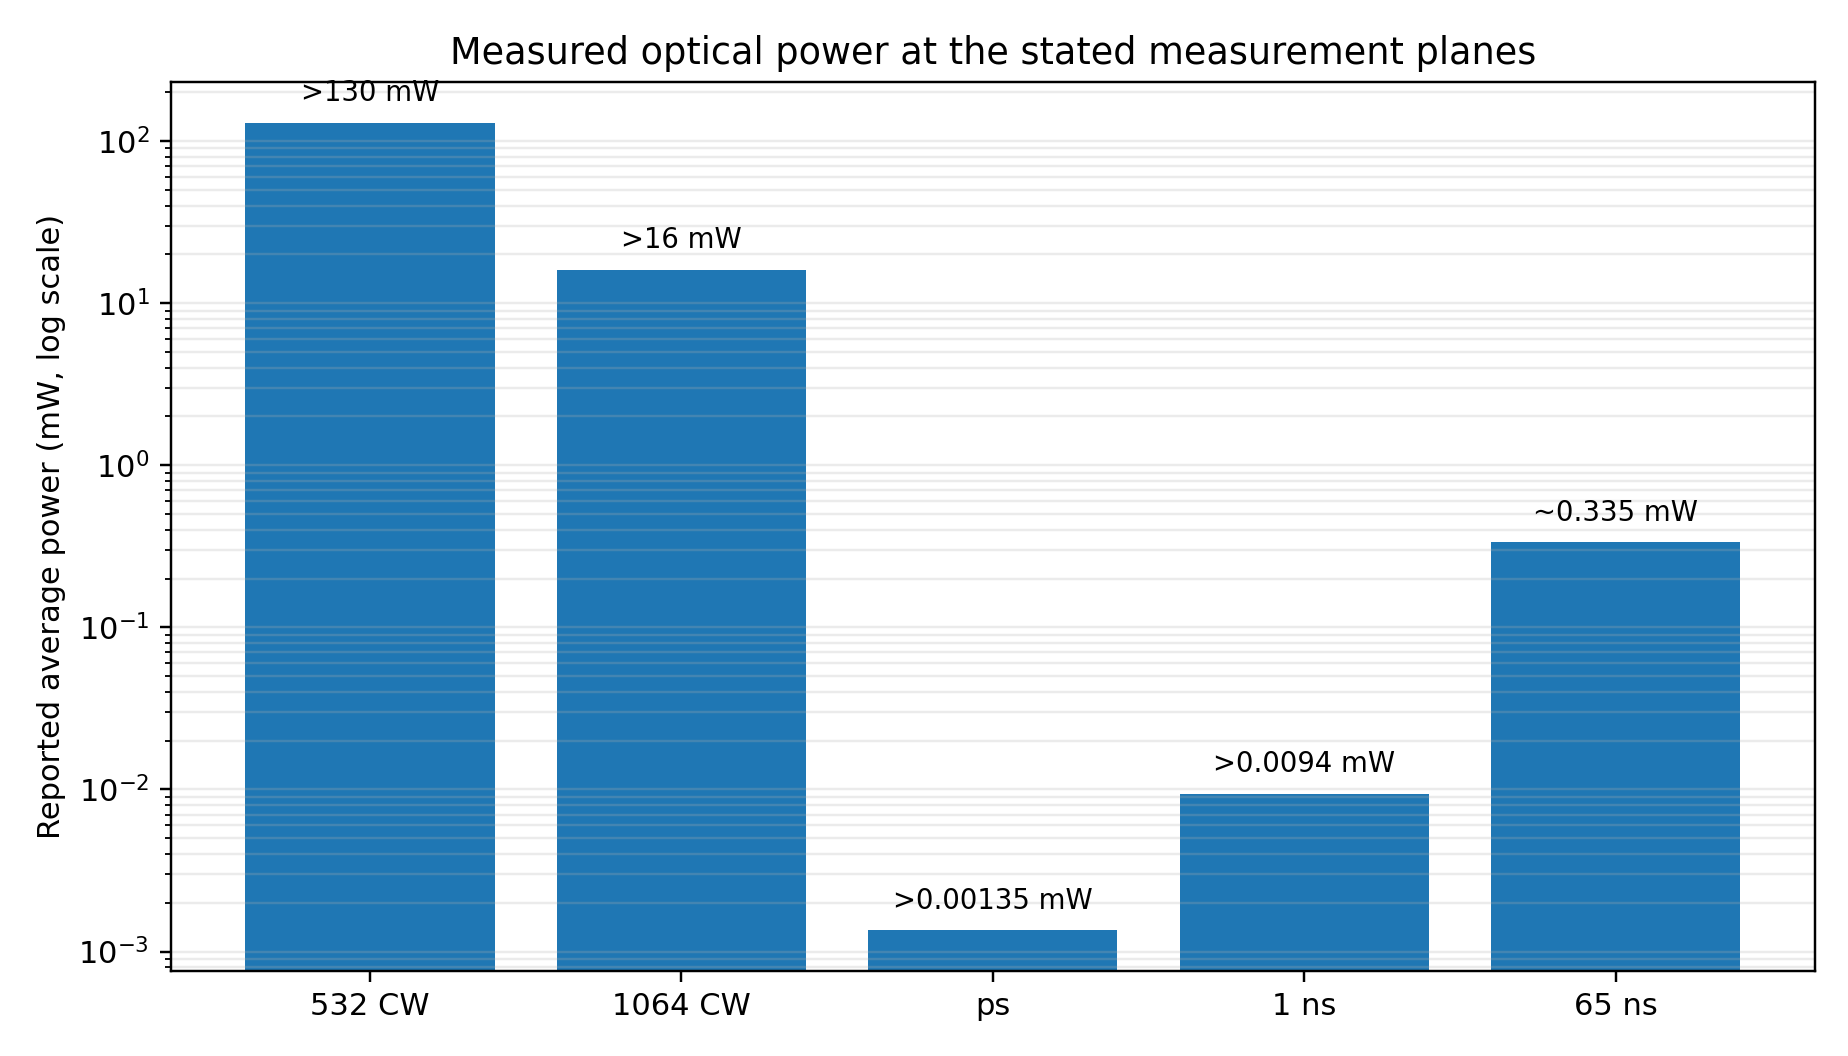

In [7]:
display(Image(filename=str(FIG / "power_measurements_v3.png")))

## Final physical interpretation

1. The spatial data support sensor-plane beam centroids, selected-lobe dimensions, ellipticity, orientation, and repeatability. The fitted M2 values are provisional sensitivity results, not standards-grade source specifications.
2. The temporal data support a 200 kHz trigger-chain repetition rate and electrical response widths. They do not directly measure picosecond or 1 ns optical durations, and the nominal 65 ns pulse remains detector-convolved.
3. The narrow spectral features are instrument/sampling limited. The broadband picosecond spectra are well sampled and support spectral-bandwidth and conditional transform-limit calculations.
4. The visible Hg calibration anchors the 532 nm region much better than the 1064 nm region. Absolute centers near 1064 nm require a near-IR reference.
5. The reported average powers support pulse-energy bounds/ranges. Peak power remains unsupported without a reliable optical pulse duration and shape.
6. The approximately two-minute warm-up and missing dedicated camera background should be treated as reproducibility limitations, not silently absorbed into a fabricated uncertainty.